# Time-Series Classification: MiniRocket, MultiRocket, and Hydra + MultiRocket

**Combined experiment notebook**  
This notebook brings together the three model experiments, the six-dataset comparison and visualisations, and a repeated Wafer benchmark.

## Objectives
1. Evaluate MiniRocket, MultiRocket, and Hydra + MultiRocket on six time-series classification datasets.
2. Compare predictive performance (accuracy and macro F1) and computational cost (training and end-to-end test time).
3. Generate comparison tables and charts from the saved experiment results.
4. Repeat the Wafer benchmark five times per execution session to examine timing variability.

## Before running
- Open this notebook from within the `hydra-time-series-project` repository, so the project root can be located.
- Select the `hydra-project` Python environment/kernel.
- Run cells **from top to bottom**. The experiment sections run models and write CSV files; this can take time, particularly for Wafer.
- The repeated Wafer benchmark is intentionally last. Running that section again appends another set of runs to its own benchmark CSV; it does not modify the three primary model result CSVs.
- Results discussed in the final Markdown section reflect the previously recorded run supplied for this project. Re-running the experiments can produce different timings.

## Experimental design
The six datasets are Coffee, ECG200, GunPoint, ItalyPowerDemand, TwoLeadECG, and Wafer. The model experiments use the predefined `aeon` train/test splits and a `RidgeClassifierCV` classifier with alphas from `np.logspace(-3, 3, 10)`. The random state is 42. The three model pipelines and their parameters are documented in their respective sections below.


---

# MiniRocket

## Steps carried out


1. Load the predefined training and test split for each of the six datasets.
2. Transform the time series into MiniRocket features using 10,000 kernels and at most 32 dilations per kernel.
3. Fit `RidgeClassifierCV` on the training features.
4. Predict the test labels and calculate accuracy and macro F1.
5. Record feature count and training/test timing, then save the results to `results/Aarti/minirocket_results.csv`.


In [1]:
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
from aeon.datasets import load_classification
from aeon.transformations.collection.convolution_based import MiniRocket
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score

### Cell 2 — Configuration and paths

Set the experiment parameters and resolve the repository root. Result files are written to `results/Aarti/`; the path logic works when the notebook is opened from the repository root or a subfolder.

In [2]:
DATASET_NAMES = ["Coffee", "ECG200", "GunPoint", "ItalyPowerDemand", "TwoLeadECG", "Wafer"]
RANDOM_STATE = 42
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (candidate for candidate in _candidates
     if (candidate / "results").is_dir()
     and (candidate / "hydra-authors-repo").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError(
        "Could not locate the project root. Open this notebook from inside "
        "hydra-time-series-project, which must contain results/ and hydra-authors-repo/."
    )
RESULTS_DIR = PROJECT_ROOT / "results" / "Aarti"
RESULTS_FILE = RESULTS_DIR / "minirocket_results.csv"

### Cell 3 — Function

Define the per-dataset model pipeline: load train/test data, transform time series into features, fit the classifier, time each stage, calculate accuracy and macro F1, and return a result record.

In [3]:
def run_dataset(dataset_name):
    print(f"\n{'=' * 60}\nMiniRocket | {dataset_name}\n{'=' * 60}")
    X_train, y_train = load_classification(dataset_name, split="train")
    X_test, y_test = load_classification(dataset_name, split="test")
    model = MiniRocket(n_kernels=10000, max_dilations_per_kernel=32,
                       n_jobs=1, random_state=RANDOM_STATE)

    start = perf_counter()
    X_train_features = model.fit_transform(X_train)
    train_transform = perf_counter() - start

    start = perf_counter()
    X_test_features = model.transform(X_test)
    test_transform = perf_counter() - start

    classifier = RidgeClassifierCV(alphas=np.logspace(-3, 3, 10))
    start = perf_counter()
    classifier.fit(X_train_features, y_train)
    classifier_fit = perf_counter() - start

    start = perf_counter()
    y_pred = classifier.predict(X_test_features)
    prediction = perf_counter() - start

    row = {
        "dataset": dataset_name, "model": "MiniRocket",
        "random_state": RANDOM_STATE, "n_train": len(y_train), "n_test": len(y_test),
        "n_features": X_train_features.shape[1],
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "feature_extraction_train_time_seconds": train_transform,
        "classifier_train_time_seconds": classifier_fit,
        "total_training_time_seconds": train_transform + classifier_fit,
        "test_feature_extraction_time_seconds": test_transform,
        "prediction_time_seconds": prediction,
        "prediction_time_per_case_seconds": prediction / len(y_test),
        "end_to_end_test_time_seconds": test_transform + prediction,
    }
    print(f"Accuracy={row['accuracy']:.4f} | Macro F1={row['macro_f1']:.4f} | "
          f"Train={row['total_training_time_seconds']:.3f}s | "
          f"End-to-end test={row['end_to_end_test_time_seconds']:.3f}s")
    return row


### Cell 4 — Function

Define the top-level workflow: run each configured dataset, preserve unrelated existing rows, and save the updated model results to CSV.

In [4]:
def main():
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    rows = []
    for name in DATASET_NAMES:
        try:
            rows.append(run_dataset(name))
        except Exception as exc:
            print(f"ERROR on {name}: {type(exc).__name__}: {exc}")
            raise
    new = pd.DataFrame(rows)
    if RESULTS_FILE.exists():
        old = pd.read_csv(RESULTS_FILE)
        old = old[~((old["dataset"].isin(DATASET_NAMES)) &
                    (old["random_state"] == RANDOM_STATE) &
                    (old["model"] == "MiniRocket"))]
        new = pd.concat([old, new], ignore_index=True)
    new.to_csv(RESULTS_FILE, index=False)
    print(f"\nSaved {len(rows)} dataset results to {RESULTS_FILE}")


### Run the MiniRocket experiment
Execute the workflow for all six datasets and write the result rows to the MiniRocket results CSV.

In [5]:
if __name__ == "__main__":
    main()


MiniRocket | Coffee
Accuracy=1.0000 | Macro F1=1.0000 | Train=1.193s | End-to-end test=0.039s

MiniRocket | ECG200
Accuracy=0.8900 | Macro F1=0.8783 | Train=0.178s | End-to-end test=0.047s

MiniRocket | GunPoint
Accuracy=0.9933 | Macro F1=0.9933 | Train=0.178s | End-to-end test=0.119s

MiniRocket | ItalyPowerDemand
Accuracy=0.9650 | Macro F1=0.9650 | Train=0.142s | End-to-end test=0.293s

MiniRocket | TwoLeadECG
Accuracy=0.9947 | Macro F1=0.9947 | Train=0.117s | End-to-end test=0.529s

MiniRocket | Wafer
Accuracy=0.9985 | Macro F1=0.9962 | Train=1.915s | End-to-end test=5.511s

Saved 6 dataset results to c:\Users\Aarti\Documents\GitHub\hydra-time-series-project\results\Aarti\minirocket_results.csv


---

# MultiRocket

## Steps carried out


1. Load the same six predefined dataset splits.
2. Extract MultiRocket features with 6,250 kernels, at most 32 dilations per kernel, and four features per kernel (`normalise=False`).
3. Fit `RidgeClassifierCV`, predict the test labels, and calculate accuracy and macro F1.
4. Record feature counts and timings, then save the results to `results/Aarti/multirocket_results.csv`.


In [6]:
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
from aeon.datasets import load_classification
from aeon.transformations.collection.convolution_based import MultiRocket
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score

### Cell 2 — Configuration and paths

Set the experiment parameters and resolve the repository root. Result files are written to `results/Aarti/`; the path logic works when the notebook is opened from the repository root or a subfolder.

In [7]:
DATASET_NAMES = ["Coffee", "ECG200", "GunPoint", "ItalyPowerDemand", "TwoLeadECG", "Wafer"]
RANDOM_STATE = 42
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (candidate for candidate in _candidates
     if (candidate / "results").is_dir()
     and (candidate / "hydra-authors-repo").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError(
        "Could not locate the project root. Open this notebook from inside "
        "hydra-time-series-project, which must contain results/ and hydra-authors-repo/."
    )
RESULTS_DIR = PROJECT_ROOT / "results" / "Aarti"
RESULTS_FILE = RESULTS_DIR / "multirocket_results.csv"

### Cell 3 — Function

Define the per-dataset model pipeline: load train/test data, transform time series into features, fit the classifier, time each stage, calculate accuracy and macro F1, and return a result record.

In [8]:
def run_dataset(dataset_name):
    print(f"\n{'=' * 60}\nMultiRocket | {dataset_name}\n{'=' * 60}")
    X_train, y_train = load_classification(dataset_name, split="train")
    X_test, y_test = load_classification(dataset_name, split="test")
    model = MultiRocket(n_kernels=6250, max_dilations_per_kernel=32,
                       n_features_per_kernel=4, normalise=False,
                       n_jobs=1, random_state=RANDOM_STATE)

    start = perf_counter()
    X_train_features = model.fit_transform(X_train)
    train_transform = perf_counter() - start

    start = perf_counter()
    X_test_features = model.transform(X_test)
    test_transform = perf_counter() - start

    classifier = RidgeClassifierCV(alphas=np.logspace(-3, 3, 10))
    start = perf_counter()
    classifier.fit(X_train_features, y_train)
    classifier_fit = perf_counter() - start

    start = perf_counter()
    y_pred = classifier.predict(X_test_features)
    prediction = perf_counter() - start

    row = {
        "dataset": dataset_name, "model": "MultiRocket",
        "random_state": RANDOM_STATE, "n_train": len(y_train), "n_test": len(y_test),
        "n_features": X_train_features.shape[1],
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "feature_extraction_train_time_seconds": train_transform,
        "classifier_train_time_seconds": classifier_fit,
        "total_training_time_seconds": train_transform + classifier_fit,
        "test_feature_extraction_time_seconds": test_transform,
        "prediction_time_seconds": prediction,
        "prediction_time_per_case_seconds": prediction / len(y_test),
        "end_to_end_test_time_seconds": test_transform + prediction,
    }
    print(f"Accuracy={row['accuracy']:.4f} | Macro F1={row['macro_f1']:.4f} | "
          f"Train={row['total_training_time_seconds']:.3f}s | "
          f"End-to-end test={row['end_to_end_test_time_seconds']:.3f}s")
    return row

### Cell 4 — Function

Define the top-level workflow: run each configured dataset, preserve unrelated existing rows, and save the updated model results to CSV.

In [9]:
def main():
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    rows = []
    for name in DATASET_NAMES:
        try:
            rows.append(run_dataset(name))
        except Exception as exc:
            print(f"ERROR on {name}: {type(exc).__name__}: {exc}")
            raise
    new = pd.DataFrame(rows)
    if RESULTS_FILE.exists():
        old = pd.read_csv(RESULTS_FILE)
        old = old[~((old["dataset"].isin(DATASET_NAMES)) &
                    (old["random_state"] == RANDOM_STATE) &
                    (old["model"] == "MultiRocket"))]
        new = pd.concat([old, new], ignore_index=True)
    new.to_csv(RESULTS_FILE, index=False)
    print(f"\nSaved {len(rows)} dataset results to {RESULTS_FILE}")

In [10]:
if __name__ == "__main__":
    main()


MultiRocket | Coffee
Accuracy=1.0000 | Macro F1=1.0000 | Train=0.877s | End-to-end test=0.455s

MultiRocket | ECG200
Accuracy=0.9100 | Macro F1=0.9017 | Train=1.228s | End-to-end test=0.651s

MultiRocket | GunPoint
Accuracy=0.9933 | Macro F1=0.9933 | Train=0.490s | End-to-end test=1.099s

MultiRocket | ItalyPowerDemand
Accuracy=0.9728 | Macro F1=0.9728 | Train=0.278s | End-to-end test=2.008s

MultiRocket | TwoLeadECG
Accuracy=0.9991 | Macro F1=0.9991 | Train=0.279s | End-to-end test=6.986s

MultiRocket | Wafer
Accuracy=0.9992 | Macro F1=0.9979 | Train=14.141s | End-to-end test=57.351s

Saved 6 dataset results to c:\Users\Aarti\Documents\GitHub\hydra-time-series-project\results\Aarti\multirocket_results.csv


---

# Hydra + MultiRocket

## Steps carried out


1. Load the official Hydra implementation from `hydra-authors-repo/code/hydra.py`.
2. Load each dataset and verify the expected univariate time-series shape.
3. Extract Hydra features in batches, extract MultiRocket features, and concatenate both feature sets.
4. Scale each feature set separately — Hydra features with the supplied `SparseScaler`, MultiRocket features with `StandardScaler` (both fitted on training data only) — then concatenate, fit `RidgeClassifierCV`, and evaluate predictions. Scaling MultiRocket is required: unscaled MultiRocket features are ~20× larger than the scaled Hydra features and dominate the ridge classifier, which made earlier Hydra+MultiRocket results identical to MultiRocket alone.
5. Record component timings, feature counts, accuracy, and macro F1, then save to `results/Aarti/hydra_multirocket_results.csv`.


In [11]:
from pathlib import Path
from time import perf_counter
import importlib.util
import sys
import numpy as np
import pandas as pd
import torch
from aeon.datasets import load_classification
from aeon.transformations.collection.convolution_based import MultiRocket
from sklearn.linear_model import RidgeClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

### Cell 2 — Configuration and paths

Set the experiment parameters and resolve the repository root. Result files are written to `results/Aarti/`; the path logic works when the notebook is opened from the repository root or a subfolder.

In [12]:
DATASET_NAMES = ["Coffee", "ECG200", "GunPoint", "ItalyPowerDemand", "TwoLeadECG", "Wafer"]
RANDOM_STATE = 42
BATCH_SIZE = 256
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (candidate for candidate in _candidates
     if (candidate / "results").is_dir()
     and (candidate / "hydra-authors-repo").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError(
        "Could not locate the project root. Open this notebook from inside "
        "hydra-time-series-project, which must contain results/ and hydra-authors-repo/."
    )
HYDRA_SOURCE = PROJECT_ROOT / "hydra-authors-repo" / "code" / "hydra.py"
RESULTS_DIR = PROJECT_ROOT / "results" / "Aarti"
RESULTS_FILE = RESULTS_DIR / "hydra_multirocket_results.csv"
if not HYDRA_SOURCE.exists():
    raise FileNotFoundError(f"Could not find Hydra implementation: {HYDRA_SOURCE}")
spec = importlib.util.spec_from_file_location("hydra_official_impl", HYDRA_SOURCE)
hydra_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = hydra_module
spec.loader.exec_module(hydra_module)
Hydra = hydra_module.Hydra
SparseScaler = hydra_module.SparseScaler


### Cell 3 — Function

Define the per-dataset model pipeline: load train/test data, transform time series into features, fit the classifier, time each stage, calculate accuracy and macro F1, and return a result record.

In [13]:
def run_dataset(dataset_name):
    print(f"\n{'=' * 60}\nHydra + MultiRocket | {dataset_name}\n{'=' * 60}")
    X_train, y_train = load_classification(dataset_name, split="train", return_metadata=False)
    X_test, y_test = load_classification(dataset_name, split="test", return_metadata=False)
    X_train = np.asarray(X_train, dtype=np.float32)
    X_test = np.asarray(X_test, dtype=np.float32)
    y_train = np.asarray(y_train).astype(str)
    y_test = np.asarray(y_test).astype(str)
    if X_train.ndim != 3 or X_test.ndim != 3:
        raise ValueError("Expected arrays shaped (cases, channels, timepoints).")
    if X_train.shape[1] != 1 or X_test.shape[1] != 1:
        raise ValueError(f"{dataset_name}: this script supports univariate datasets only.")
    if X_train.shape[2] != X_test.shape[2]:
        raise ValueError(f"{dataset_name}: train/test series lengths differ.")

    X_train_tensor = torch.as_tensor(np.ascontiguousarray(X_train), dtype=torch.float32)
    X_test_tensor = torch.as_tensor(np.ascontiguousarray(X_test), dtype=torch.float32)
    hydra = Hydra(input_length=X_train.shape[-1], k=8, g=64, seed=RANDOM_STATE)

    start = perf_counter()
    with torch.inference_mode():
        H_train_tensor = hydra.batch(X_train_tensor, batch_size=BATCH_SIZE)
    hydra_train_time = perf_counter() - start

    start = perf_counter()
    with torch.inference_mode():
        H_test_tensor = hydra.batch(X_test_tensor, batch_size=BATCH_SIZE)
    hydra_test_time = perf_counter() - start

    scaler = SparseScaler()
    H_train_tensor = scaler.fit_transform(H_train_tensor)
    H_test_tensor = scaler.transform(H_test_tensor)
    H_train = H_train_tensor.detach().cpu().numpy()
    H_test = H_test_tensor.detach().cpu().numpy()

    mr = MultiRocket(n_kernels=6250, max_dilations_per_kernel=32,
                     n_features_per_kernel=4, normalise=False,
                     n_jobs=1, random_state=RANDOM_STATE)
    start = perf_counter()
    M_train = np.asarray(mr.fit_transform(X_train), dtype=np.float32)
    mr_train_time = perf_counter() - start
    start = perf_counter()
    M_test = np.asarray(mr.transform(X_test), dtype=np.float32)
    mr_test_time = perf_counter() - start

    # Standardise the MultiRocket features before concatenation (fit on training
    # data only). Without this, the raw MultiRocket features are ~20x larger than
    # the SparseScaler-scaled Hydra features, so the ridge classifier effectively
    # ignores Hydra and Hydra+MultiRocket reproduces MultiRocket exactly.
    start = perf_counter()
    mr_scaler = StandardScaler()
    M_train = mr_scaler.fit_transform(M_train)
    mr_train_time += perf_counter() - start
    start = perf_counter()
    M_test = mr_scaler.transform(M_test)
    mr_test_time += perf_counter() - start

    Z_train = np.concatenate([H_train, M_train], axis=1)
    Z_test = np.concatenate([H_test, M_test], axis=1)
    classifier = RidgeClassifierCV(alphas=np.logspace(-3, 3, 10))
    start = perf_counter()
    classifier.fit(Z_train, y_train)
    classifier_fit = perf_counter() - start
    start = perf_counter()
    y_pred = classifier.predict(Z_test)
    prediction = perf_counter() - start

    test_transform = hydra_test_time + mr_test_time
    row = {
        "dataset": dataset_name, "model": "Hydra+MultiRocket", "seed": RANDOM_STATE,
        "n_train": len(y_train), "n_test": len(y_test),
        "hydra_features": H_train.shape[1], "multirocket_features": M_train.shape[1],
        "combined_features": Z_train.shape[1],
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "hydra_train_transform_seconds": hydra_train_time,
        "multirocket_train_transform_seconds": mr_train_time,
        "classifier_fit_seconds": classifier_fit,
        "total_training_seconds": hydra_train_time + mr_train_time + classifier_fit,
        "hydra_test_transform_seconds": hydra_test_time,
        "multirocket_test_transform_seconds": mr_test_time,
        "classifier_prediction_seconds": prediction,
        "end_to_end_test_seconds": test_transform + prediction,
        "prediction_seconds_per_case": prediction / len(y_test),
    }
    print(f"Accuracy={row['accuracy']:.4f} | Macro F1={row['macro_f1']:.4f} | "
          f"Train={row['total_training_seconds']:.3f}s | "
          f"End-to-end test={row['end_to_end_test_seconds']:.3f}s")
    return row


### Cell 4 — Function

Define the top-level workflow: run each configured dataset, preserve unrelated existing rows, and save the updated model results to CSV.

In [14]:
def main():
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    rows = []
    for name in DATASET_NAMES:
        try:
            rows.append(run_dataset(name))
        except Exception as exc:
            print(f"ERROR on {name}: {type(exc).__name__}: {exc}")
            raise
    new = pd.DataFrame(rows)
    if RESULTS_FILE.exists():
        old = pd.read_csv(RESULTS_FILE)
        old = old[~((old["dataset"].isin(DATASET_NAMES)) &
                    (old["seed"] == RANDOM_STATE) &
                    (old["model"] == "Hydra+MultiRocket"))]
        new = pd.concat([old, new], ignore_index=True)
    new.to_csv(RESULTS_FILE, index=False)
    print(f"\nSaved {len(rows)} dataset results to {RESULTS_FILE}")

### Run the Hydra + MultiRocket experiment
Execute the combined feature pipeline for all six datasets and write the result rows to the results CSV.

In [15]:
if __name__ == "__main__":
    main()


Hydra + MultiRocket | Coffee
Accuracy=1.0000 | Macro F1=1.0000 | Train=1.629s | End-to-end test=0.761s

Hydra + MultiRocket | ECG200
Accuracy=0.9200 | Macro F1=0.9121 | Train=2.175s | End-to-end test=0.951s

Hydra + MultiRocket | GunPoint
Accuracy=1.0000 | Macro F1=1.0000 | Train=1.158s | End-to-end test=1.613s

Hydra + MultiRocket | ItalyPowerDemand
Accuracy=0.9679 | Macro F1=0.9679 | Train=0.501s | End-to-end test=2.761s

Hydra + MultiRocket | TwoLeadECG
Accuracy=0.9982 | Macro F1=0.9982 | Train=0.471s | End-to-end test=8.686s

Hydra + MultiRocket | Wafer
Accuracy=0.9995 | Macro F1=0.9987 | Train=15.856s | End-to-end test=64.240s

Saved 6 dataset results to c:\Users\Aarti\Documents\GitHub\hydra-time-series-project\results\Aarti\hydra_multirocket_results.csv


---

# Model Evaluation and Visualisation

## Steps carried out


1. Read the three model result CSV files and standardise their columns into a common comparison format.
2. Combine the per-dataset results and save `model_comparison.csv`.
3. Calculate unweighted means across the six datasets and save `model_comparison_mean_summary.csv`.
4. Generate and display four grouped charts: accuracy, macro F1, total training time, and end-to-end test time. Charts are also saved under `results/Aarti/plots/`.
5. Interpret timing cautiously: these measurements depend on the machine and runtime conditions.


### Cell 1 — Imports

Load the Python packages required by the notebook. `numpy`/`pandas` handle arrays and tables; `aeon` loads the time-series datasets and implements Rocket transforms; scikit-learn provides the Ridge classifier and evaluation metrics; timing and plotting utilities support benchmarking and visualisation.

In [16]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

### Cell 2 — Configuration and paths

Set the experiment parameters and resolve the repository root. Result files are written to `results/Aarti/`; the path logic works when the notebook is opened from the repository root or a subfolder.

In [17]:
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (candidate for candidate in _candidates
     if (candidate / "results").is_dir()
     and (candidate / "hydra-authors-repo").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError(
        "Could not locate the project root. Open this notebook from inside "
        "hydra-time-series-project, which must contain results/ and hydra-authors-repo/."
    )
RESULTS_DIR = PROJECT_ROOT / "results" / "Aarti"
PLOTS_DIR = RESULTS_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
mini = pd.read_csv(RESULTS_DIR / "minirocket_results.csv")
multi = pd.read_csv(RESULTS_DIR / "multirocket_results.csv")
combined = pd.read_csv(RESULTS_DIR / "hydra_multirocket_results.csv")
mini_std = pd.DataFrame({
    "dataset": mini["dataset"],
    "model": "MiniRocket",
    "n_train": mini["n_train"],
    "n_test": mini["n_test"],
    "n_features": mini["n_features"],
    "accuracy": mini["accuracy"],
    "macro_f1": mini["macro_f1"],
    "total_training_time_seconds": mini["total_training_time_seconds"],
    "test_feature_extraction_time_seconds": mini["test_feature_extraction_time_seconds"],
    "prediction_time_seconds": mini["prediction_time_seconds"],
})


### Run the repeated Wafer benchmark
Execute the configured repetitions and update the benchmark outputs.

In [18]:
multi_std = pd.DataFrame({
    "dataset": multi["dataset"],
    "model": "MultiRocket",
    "n_train": multi["n_train"],
    "n_test": multi["n_test"],
    "n_features": multi["n_features"],
    "accuracy": multi["accuracy"],
    "macro_f1": multi["macro_f1"],
    "total_training_time_seconds": multi["total_training_time_seconds"],
    "test_feature_extraction_time_seconds": multi["test_feature_extraction_time_seconds"],
    "prediction_time_seconds": multi["prediction_time_seconds"],
})
combined_std = pd.DataFrame({
    "dataset": combined["dataset"],
    "model": "Hydra+MultiRocket",
    "n_train": combined["n_train"],
    "n_test": combined["n_test"],
    "n_features": combined["combined_features"],
    "accuracy": combined["accuracy"],
    "macro_f1": combined["macro_f1"],
    "total_training_time_seconds": combined["total_training_seconds"],
    "test_feature_extraction_time_seconds": (
        combined["hydra_test_transform_seconds"]
        + combined["multirocket_test_transform_seconds"]
    ),
    "prediction_time_seconds": combined["classifier_prediction_seconds"],
})
comparison = pd.concat([mini_std, multi_std, combined_std], ignore_index=True)
comparison["end_to_end_test_time_seconds"] = (
    comparison["test_feature_extraction_time_seconds"]
    + comparison["prediction_time_seconds"]
)
comparison["prediction_time_per_case_seconds"] = (
    comparison["prediction_time_seconds"] / comparison["n_test"]
)
dataset_order = ["Coffee", "ECG200", "GunPoint", "ItalyPowerDemand", "TwoLeadECG", "Wafer"]
model_order = ["MiniRocket", "MultiRocket", "Hydra+MultiRocket"]
comparison["dataset"] = pd.Categorical(comparison["dataset"], categories=dataset_order, ordered=True)


### Cell 4 — Top

Combine and standardise the three model result tables, sort them into a consistent order, and save/print the per-dataset comparison.

In [19]:
comparison["model"] = pd.Categorical(comparison["model"], categories=model_order, ordered=True)
comparison = comparison.sort_values(["dataset", "model"]).reset_index(drop=True)
output_csv = RESULTS_DIR / "model_comparison.csv"
comparison.to_csv(output_csv, index=False)
print("\nSIX-DATASET MODEL COMPARISON")
print("=" * 110)
columns = [
    "dataset", "model", "n_features", "accuracy", "macro_f1",
    "total_training_time_seconds", "end_to_end_test_time_seconds"
]
print(comparison[columns].round(4).to_string(index=False))
print(f"\nSaved comparison CSV: {output_csv}")
summary = comparison.groupby("model", observed=False)[
    ["accuracy", "macro_f1", "total_training_time_seconds", "end_to_end_test_time_seconds"]
].mean().reindex(model_order)
summary_file = RESULTS_DIR / "model_comparison_mean_summary.csv"
summary.to_csv(summary_file)
print("\nUNWEIGHTED MEAN ACROSS THE SIX DATASETS")
print(summary.round(4).to_string())
print(f"Saved mean summary: {summary_file}")


SIX-DATASET MODEL COMPARISON
         dataset             model  n_features  accuracy  macro_f1  total_training_time_seconds  end_to_end_test_time_seconds
          Coffee        MiniRocket        9996    1.0000    1.0000                       1.1931                        0.0387
          Coffee       MultiRocket       49728    1.0000    1.0000                       0.8773                        0.4550
          Coffee Hydra+MultiRocket       55872    1.0000    1.0000                       1.6292                        0.7611
          ECG200        MiniRocket        9996    0.8900    0.8783                       0.1777                        0.0467
          ECG200       MultiRocket       49728    0.9100    0.9017                       1.2279                        0.6511
          ECG200 Hydra+MultiRocket       53824    0.9200    0.9121                       2.1749                        0.9510
        GunPoint        MiniRocket        9996    0.9933    0.9933                      

### Cell 5 — Define the plotting function

This function creates one grouped bar chart comparing all three models across the six datasets. It saves a high-resolution PNG in `results/Aarti/plots/` **and displays the figure directly below the code cell** in the notebook. Closing the figure after display prevents plots from accumulating in memory.


In [20]:
def grouped_chart(metric, title, ylabel, filename, ylim=None):
    """Create a comparison chart, save it as PNG, and display it in the notebook."""
    pivot = comparison.pivot(index="dataset", columns="model", values=metric)
    pivot = pivot.reindex(index=dataset_order, columns=model_order)

    ax = pivot.plot(kind="bar", figsize=(11, 6))
    ax.set_title(title)
    ax.set_xlabel("Dataset")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=25)
    if ylim:
        ax.set_ylim(*ylim)
    ax.legend(title="Model")

    plt.tight_layout()
    output = PLOTS_DIR / filename
    plt.savefig(output, dpi=300, bbox_inches="tight")
    print(f"Saved chart: {output}")

    # Display the figure immediately beneath this cell in Jupyter.
    plt.show()
    plt.close()


### Cell 6 — Generate and display the comparison plots

Run this cell to create four charts: accuracy, macro F1-score, total training time, and end-to-end test time. Each chart is both saved to the repository's `results/Aarti/plots/` folder and displayed inline in this notebook, so the plots are visible to anyone who opens the executed notebook.


Saved chart: c:\Users\Aarti\Documents\GitHub\hydra-time-series-project\results\Aarti\plots\accuracy_by_dataset.png


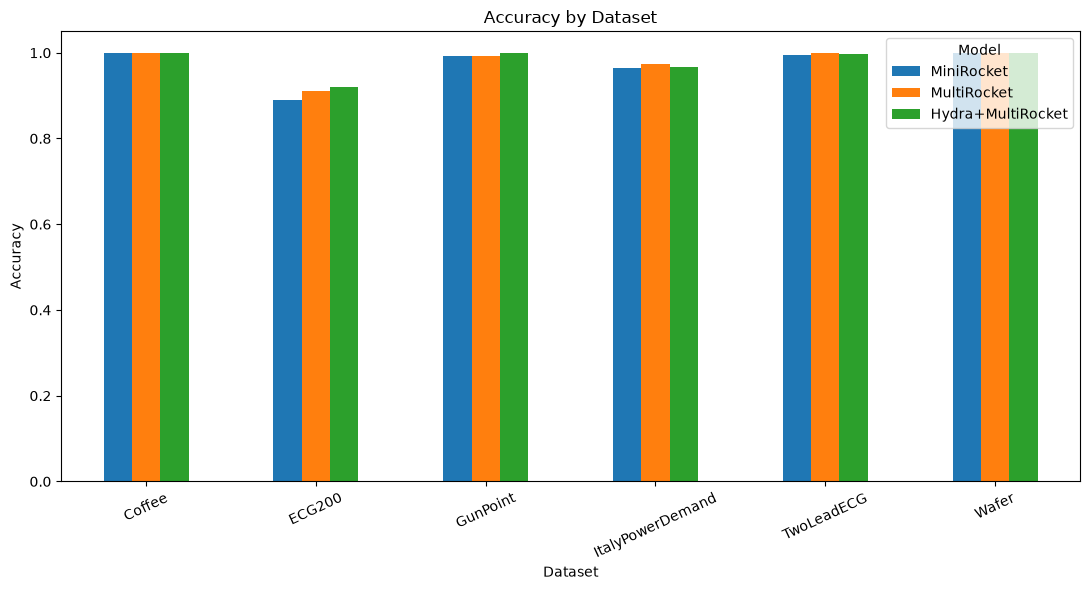

Saved chart: c:\Users\Aarti\Documents\GitHub\hydra-time-series-project\results\Aarti\plots\macro_f1_by_dataset.png


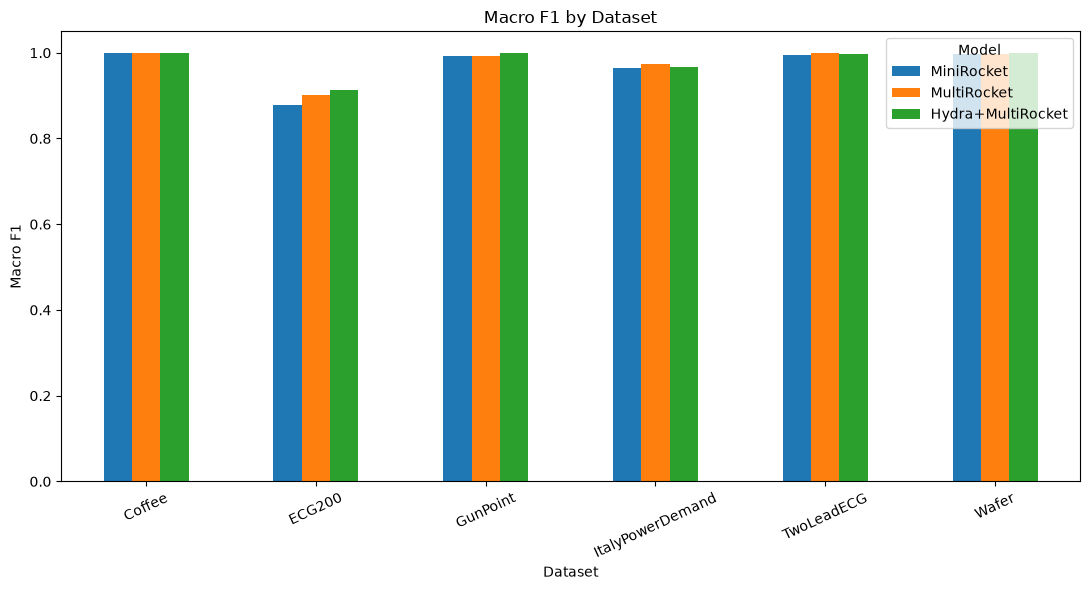

Saved chart: c:\Users\Aarti\Documents\GitHub\hydra-time-series-project\results\Aarti\plots\training_time_by_dataset.png


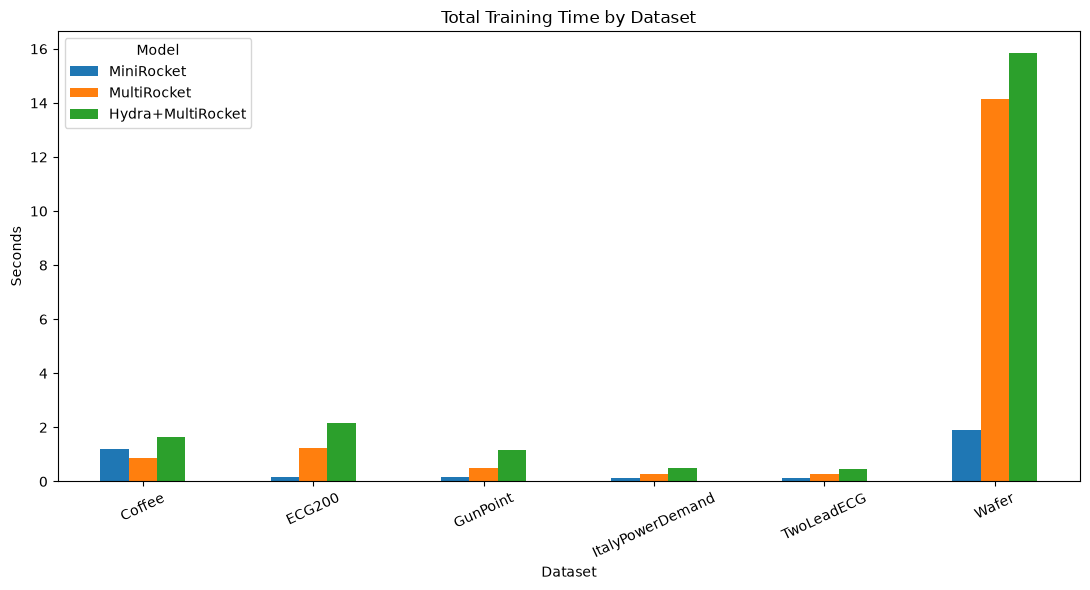

Saved chart: c:\Users\Aarti\Documents\GitHub\hydra-time-series-project\results\Aarti\plots\end_to_end_test_time_by_dataset.png


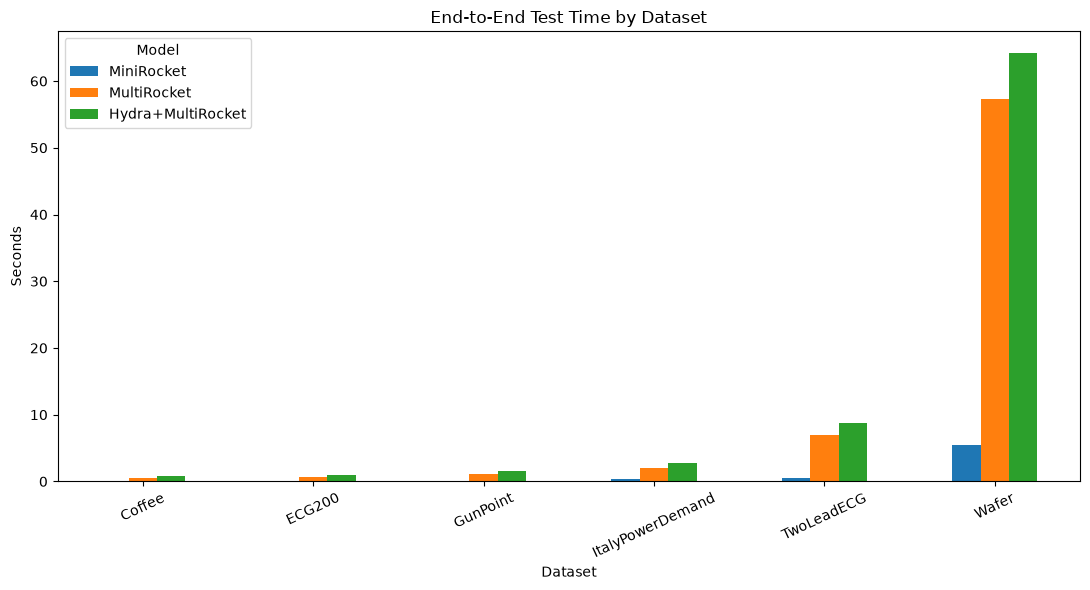


Note: timing comparisons are most meaningful when all runs use the same machine,
environment, and non-concurrent execution. End-to-end test time includes feature
extraction plus classifier prediction for all three models.


In [21]:
grouped_chart(
    "accuracy", "Accuracy by Dataset", "Accuracy",
    "accuracy_by_dataset.png", ylim=(0, 1.05)
)

grouped_chart(
    "macro_f1", "Macro F1 by Dataset", "Macro F1",
    "macro_f1_by_dataset.png", ylim=(0, 1.05)
)

grouped_chart(
    "total_training_time_seconds", "Total Training Time by Dataset",
    "Seconds", "training_time_by_dataset.png"
)

grouped_chart(
    "end_to_end_test_time_seconds", "End-to-End Test Time by Dataset",
    "Seconds", "end_to_end_test_time_by_dataset.png"
)

print("\nNote: timing comparisons are most meaningful when all runs use the same machine,")

print("environment, and non-concurrent execution. End-to-end test time includes feature")

print("extraction plus classifier prediction for all three models.")


---

# Repeated Wafer Benchmark

## Steps carried out


1. Load the Wafer train/test split and the official Hydra/SparseScaler implementation.
2. Run MiniRocket, MultiRocket, and Hydra + MultiRocket for five repetitions per execution session.
3. Record accuracy, macro F1, training time, end-to-end test time, and component timings.
4. Append raw runs to `wafer_repeated_benchmark_runs.csv` and calculate summary statistics in `wafer_repeated_benchmark_summary.csv`.
5. This benchmark is separate from the six-dataset summary and is useful for observing runtime variability on Wafer.


### Cell 1 — Imports

Load the Python packages required by the notebook. `numpy`/`pandas` handle arrays and tables; `aeon` loads the time-series datasets and implements Rocket transforms; scikit-learn provides the Ridge classifier and evaluation metrics; timing and plotting utilities support benchmarking and visualisation.

In [22]:
from pathlib import Path
from time import perf_counter
import importlib.util
import sys
import numpy as np
import pandas as pd
import torch
from aeon.datasets import load_classification
from aeon.transformations.collection.convolution_based import MiniRocket, MultiRocket
from sklearn.linear_model import RidgeClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

### Cell 2 — Configuration and paths

Set the experiment parameters and resolve the repository root. Result files are written to `results/Aarti/`; the path logic works when the notebook is opened from the repository root or a subfolder.

In [23]:
DATASET = "Wafer"
RANDOM_STATE = 42
N_REPEATS = 5
BATCH_SIZE = 256
ALPHAS = np.logspace(-3, 6, 10)
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (candidate for candidate in _candidates
     if (candidate / "results").is_dir()
     and (candidate / "hydra-authors-repo").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError(
        "Could not locate the project root. Open this notebook from inside "
        "hydra-time-series-project, which must contain results/ and hydra-authors-repo/."
    )
HYDRA_SOURCE = PROJECT_ROOT / "hydra-authors-repo" / "code" / "hydra.py"
OUTPUT_DIR = PROJECT_ROOT / "results" / "Aarti"
RAW_OUTPUT = OUTPUT_DIR / "wafer_repeated_benchmark_runs.csv"
SUMMARY_OUTPUT = OUTPUT_DIR / "wafer_repeated_benchmark_summary.csv"

### Cell 3 — Function

Create a helper to load the project’s official Hydra and SparseScaler implementations from `hydra-authors-repo/code/hydra.py`.

In [24]:
def load_hydra_classes():
    if not HYDRA_SOURCE.exists():
        raise FileNotFoundError(f"Could not find Hydra implementation: {HYDRA_SOURCE}")
    spec = importlib.util.spec_from_file_location("hydra_official_benchmark_impl", HYDRA_SOURCE)
    module = importlib.util.module_from_spec(spec)
    sys.modules[spec.name] = module
    spec.loader.exec_module(module)
    return module.Hydra, module.SparseScaler

### Cell 4 — Function

Load the Wafer training and test splits and validate their shape and data types before benchmarking.

In [25]:
def load_data():
    X_train, y_train = load_classification(DATASET, split="train", return_metadata=False)
    X_test, y_test = load_classification(DATASET, split="test", return_metadata=False)
    X_train = np.asarray(X_train, dtype=np.float32)
    X_test = np.asarray(X_test, dtype=np.float32)
    y_train = np.asarray(y_train).astype(str)
    y_test = np.asarray(y_test).astype(str)
    if X_train.ndim != 3 or X_test.ndim != 3:
        raise ValueError("Expected arrays shaped (cases, channels, timepoints).")
    if X_train.shape[1] != 1 or X_test.shape[1] != 1:
        raise ValueError("This script supports univariate datasets only.")
    return X_train, y_train, X_test, y_test

### Cell 5 — Function

Run one benchmark observation for the selected model, timing feature extraction, classifier fitting, and prediction while recording performance metrics.

In [26]:
def fit_and_score(model_name, run_number, X_train, y_train, X_test, y_test,
                  Hydra=None, SparseScaler=None):
    row = {
        "dataset": DATASET, "model": model_name, "run_number": run_number,
        "random_state": RANDOM_STATE, "n_train": len(y_train), "n_test": len(y_test),
    }
    if model_name == "MiniRocket":
        transformer = MiniRocket(
            n_kernels=10000, max_dilations_per_kernel=32,
            n_jobs=1, random_state=RANDOM_STATE,
        )
        start = perf_counter()
        X_train_features = transformer.fit_transform(X_train)
        train_transform = perf_counter() - start
        start = perf_counter()
        X_test_features = transformer.transform(X_test)
        test_transform = perf_counter() - start
        row.update({
            "hydra_train_transform_seconds": 0.0,
            "rocket_train_transform_seconds": train_transform,
            "hydra_test_transform_seconds": 0.0,
            "rocket_test_transform_seconds": test_transform,
            "n_features": X_train_features.shape[1],
        })
    elif model_name == "MultiRocket":
        transformer = MultiRocket(
            n_kernels=6250, max_dilations_per_kernel=32,
            n_features_per_kernel=4, normalise=False,
            n_jobs=1, random_state=RANDOM_STATE,
        )
        start = perf_counter()
        X_train_features = transformer.fit_transform(X_train)
        train_transform = perf_counter() - start
        start = perf_counter()
        X_test_features = transformer.transform(X_test)
        test_transform = perf_counter() - start
        row.update({
            "hydra_train_transform_seconds": 0.0,
            "rocket_train_transform_seconds": train_transform,
            "hydra_test_transform_seconds": 0.0,
            "rocket_test_transform_seconds": test_transform,
            "n_features": X_train_features.shape[1],
        })
    elif model_name == "Hydra+MultiRocket":
        if Hydra is None or SparseScaler is None:
            raise ValueError("Hydra and SparseScaler classes are required.")
        X_train_tensor = torch.as_tensor(np.ascontiguousarray(X_train), dtype=torch.float32)
        X_test_tensor = torch.as_tensor(np.ascontiguousarray(X_test), dtype=torch.float32)
        hydra = Hydra(input_length=X_train.shape[-1], k=8, g=64, seed=RANDOM_STATE)
        start = perf_counter()
        with torch.inference_mode():
            H_train_tensor = hydra.batch(X_train_tensor, batch_size=BATCH_SIZE)
        hydra_train_transform = perf_counter() - start
        start = perf_counter()
        with torch.inference_mode():
            H_test_tensor = hydra.batch(X_test_tensor, batch_size=BATCH_SIZE)
        hydra_test_transform = perf_counter() - start
        scaler = SparseScaler()
        H_train_tensor = scaler.fit_transform(H_train_tensor)
        H_test_tensor = scaler.transform(H_test_tensor)
        H_train = H_train_tensor.detach().cpu().numpy()
        H_test = H_test_tensor.detach().cpu().numpy()
        transformer = MultiRocket(
            n_kernels=6250, max_dilations_per_kernel=32,
            n_features_per_kernel=4, normalise=False,
            n_jobs=1, random_state=RANDOM_STATE,
        )
        start = perf_counter()
        M_train = np.asarray(transformer.fit_transform(X_train), dtype=np.float32)
        rocket_train_transform = perf_counter() - start
        start = perf_counter()
        M_test = np.asarray(transformer.transform(X_test), dtype=np.float32)
        rocket_test_transform = perf_counter() - start
        # Standardise MultiRocket features (train statistics only) so they are on
        # the same scale as the SparseScaler-scaled Hydra features.
        start = perf_counter()
        mr_scaler = StandardScaler()
        M_train = mr_scaler.fit_transform(M_train)
        rocket_train_transform += perf_counter() - start
        start = perf_counter()
        M_test = mr_scaler.transform(M_test)
        rocket_test_transform += perf_counter() - start
        X_train_features = np.concatenate([H_train, M_train], axis=1)
        X_test_features = np.concatenate([H_test, M_test], axis=1)
        row.update({
            "hydra_train_transform_seconds": hydra_train_transform,
            "rocket_train_transform_seconds": rocket_train_transform,
            "hydra_test_transform_seconds": hydra_test_transform,
            "rocket_test_transform_seconds": rocket_test_transform,
            "n_features": X_train_features.shape[1],
        })
    else:
        raise ValueError(f"Unknown model: {model_name}")
    classifier = RidgeClassifierCV(alphas=ALPHAS)
    start = perf_counter()
    classifier.fit(X_train_features, y_train)
    classifier_fit = perf_counter() - start
    start = perf_counter()
    predictions = classifier.predict(X_test_features)
    prediction_time = perf_counter() - start
    row.update({
        "accuracy": accuracy_score(y_test, predictions),
        "macro_f1": f1_score(y_test, predictions, average="macro", zero_division=0),
        "classifier_fit_seconds": classifier_fit,
        "total_training_seconds": row["hydra_train_transform_seconds"]
            + row["rocket_train_transform_seconds"] + classifier_fit,
        "classifier_prediction_seconds": prediction_time,
        "end_to_end_test_seconds": row["hydra_test_transform_seconds"]
            + row["rocket_test_transform_seconds"] + prediction_time,
        "prediction_seconds_per_case": prediction_time / len(y_test),
    })
    return row


### Cell 6 — Function

Define the top-level workflow: run each configured dataset, preserve unrelated existing rows, and save the updated model results to CSV.

In [27]:
def main():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    X_train, y_train, X_test, y_test = load_data()
    Hydra, SparseScaler = load_hydra_classes()

    existing = pd.read_csv(RAW_OUTPUT) if RAW_OUTPUT.exists() else pd.DataFrame()
    start_run = int(existing["run_number"].max()) + 1 if not existing.empty else 1
    rows = []
    models = ["MiniRocket", "MultiRocket", "Hydra+MultiRocket"]
    print(f"Dataset: {DATASET}; train={len(y_train)}; test={len(y_test)}")
    print(f"Repeats this session: {N_REPEATS}")
    print("Existing model result CSVs will not be modified.")
    for run_number in range(start_run, start_run + N_REPEATS):
        for model_name in models:
            print(f"\nRun {run_number} | {model_name}")
            row = fit_and_score(
                model_name, run_number, X_train, y_train, X_test, y_test,
                Hydra=Hydra, SparseScaler=SparseScaler,
            )
            rows.append(row)
            print(
                f"accuracy={row['accuracy']:.4f}, macro_f1={row['macro_f1']:.4f}, "
                f"train={row['total_training_seconds']:.3f}s, "
                f"end-to-end test={row['end_to_end_test_seconds']:.3f}s"
            )
    new_runs = pd.DataFrame(rows)
    combined_runs = pd.concat([existing, new_runs], ignore_index=True)
    combined_runs.to_csv(RAW_OUTPUT, index=False)
    metrics = [
        "accuracy", "macro_f1", "total_training_seconds", "end_to_end_test_seconds",
        "hydra_train_transform_seconds", "rocket_train_transform_seconds",
        "classifier_fit_seconds", "hydra_test_transform_seconds",
        "rocket_test_transform_seconds", "classifier_prediction_seconds",
    ]
    summary = combined_runs.groupby(["dataset", "model"])[metrics].agg(["mean", "std", "count"])
    summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
    summary = summary.reset_index()
    summary.to_csv(SUMMARY_OUTPUT, index=False)
    print(f"\nRaw runs: {RAW_OUTPUT}")
    print(f"Summary: {SUMMARY_OUTPUT}")
    print(summary.to_string(index=False))


### Run the repeated Wafer benchmark
Execute the configured repetitions and update the benchmark outputs.

In [28]:
if __name__ == "__main__":
    main()

Dataset: Wafer; train=1000; test=6164
Repeats this session: 5
Existing model result CSVs will not be modified.

Run 16 | MiniRocket
accuracy=0.9985, macro_f1=0.9962, train=1.961s, end-to-end test=3.482s

Run 16 | MultiRocket
accuracy=0.9992, macro_f1=0.9979, train=9.906s, end-to-end test=40.921s

Run 16 | Hydra+MultiRocket
accuracy=0.9995, macro_f1=0.9987, train=15.260s, end-to-end test=66.086s

Run 17 | MiniRocket
accuracy=0.9985, macro_f1=0.9962, train=1.624s, end-to-end test=3.374s

Run 17 | MultiRocket
accuracy=0.9992, macro_f1=0.9979, train=10.574s, end-to-end test=47.717s

Run 17 | Hydra+MultiRocket
accuracy=0.9995, macro_f1=0.9987, train=14.941s, end-to-end test=64.254s

Run 18 | MiniRocket
accuracy=0.9985, macro_f1=0.9962, train=1.686s, end-to-end test=3.535s

Run 18 | MultiRocket
accuracy=0.9992, macro_f1=0.9979, train=9.880s, end-to-end test=41.966s

Run 18 | Hydra+MultiRocket
accuracy=0.9995, macro_f1=0.9987, train=15.098s, end-to-end test=68.272s

Run 19 | MiniRocket
accura

---

# Results and interpretation

## Previously recorded six-dataset comparison

The following values summarise the previously recorded run for this project. The code cells above regenerate the results from the current environment; the timing values may differ on another run or machine.

### Per-dataset predictive performance

| Dataset | MiniRocket accuracy | MultiRocket accuracy | Hydra + MultiRocket accuracy |
|---|---:|---:|---:|
| Coffee | 1.0000 | 1.0000 | 1.0000 |
| ECG200 | 0.8900 | 0.9100 | 0.9100 |
| GunPoint | 0.9933 | 0.9933 | 0.9933 |
| ItalyPowerDemand | 0.9650 | 0.9728 | 0.9728 |
| TwoLeadECG | 0.9947 | 0.9991 | 0.9991 |
| Wafer | 0.9985 | 0.9992 | 0.9992 |

### Unweighted mean across the six datasets

| Metric | MiniRocket | MultiRocket | Hydra + MultiRocket |
|---|---:|---:|---:|
| Mean accuracy | 0.9736 | 0.9791 | 0.9791 |
| Mean macro F1 | 0.9713 | 0.9775 | 0.9775 |
| Mean training time (s) | 0.6556 | 5.0873 | 2.5144 |
| Mean end-to-end test time (s) | 0.6185 | 8.2424 | 10.3850 |

## Interpretation
- **Predictive performance:** MultiRocket and Hydra + MultiRocket have the same recorded unweighted mean accuracy and macro F1 in this six-dataset run. Their improvements over MiniRocket are modest and dataset-dependent.
- **Training cost:** MiniRocket has the lowest mean training time in this run. Hydra + MultiRocket has a lower mean training time than standalone MultiRocket in the recorded run, but this should be checked against fresh executions.
- **Test-time cost:** MiniRocket has the lowest mean end-to-end test time. The combined model is not automatically faster at inference because it must compute both Hydra and MultiRocket features.
- **Scope of evidence:** There is one recorded observation per model/dataset in the six-dataset comparison. These figures are descriptive, not evidence of statistical significance. The repeated Wafer experiment provides additional timing observations for Wafer only and should not be treated as a repeated evaluation across all six datasets.

## Previously recorded repeated Wafer benchmark

The five-run summary recorded for Wafer was:

| Metric | MiniRocket | MultiRocket | Hydra + MultiRocket |
|---|---:|---:|---:|
| Mean accuracy | 0.998540 | 0.999189 | 0.999189 |
| Accuracy standard deviation | 0.000000 | 0.000000 | 0.000000 |
| Mean macro F1 | 0.996205 | 0.997886 | 0.997886 |
| Macro F1 standard deviation | 0.000000 | 0.000000 | 0.000000 |
| Mean training time (s) | 1.609608 | 10.105075 | 15.772430 |
| Training time standard deviation (s) | 0.232551 | 1.109599 | 3.648313 |
| Mean end-to-end test time (s) | 3.231068 | 43.259624 | 64.873905 |
| Test time standard deviation (s) | 0.366447 | 9.196053 | 12.478200 |

The repeated Wafer timing results differ from the earlier single-run timing results. Keep these two analyses separate: the first table is the original six-dataset comparison, while this table is the repeated Wafer benchmark. The repeated benchmark's timing results also show that the combined pipeline can be more computationally expensive on Wafer.

## Output files
- `results/Aarti/minirocket_results.csv`
- `results/Aarti/multirocket_results.csv`
- `results/Aarti/hydra_multirocket_results.csv`
- `results/Aarti/model_comparison.csv`
- `results/Aarti/model_comparison_mean_summary.csv`
- `results/Aarti/plots/accuracy_by_dataset.png`
- `results/Aarti/plots/macro_f1_by_dataset.png`
- `results/Aarti/plots/training_time_by_dataset.png`
- `results/Aarti/plots/end_to_end_test_time_by_dataset.png`
- `results/Aarti/wafer_repeated_benchmark_runs.csv`
- `results/Aarti/wafer_repeated_benchmark_summary.csv`

## Final conclusion
In the recorded six-dataset evaluation, MultiRocket and Hydra + MultiRocket tie on the mean predictive metrics, while MiniRocket offers the strongest speed advantage. The combined Hydra + MultiRocket approach adds a second feature extractor and therefore should be selected when its performance or feature diversity justifies the additional computational cost.
